# Part II · Notebook 03 — X3: is tuning for fidelity a privacy risk?

Part I used library defaults and found that fidelity and leakage rise together *across* generators. Practitioners tune
hyper-parameters to raise fidelity. Here we measure what that does to leakage *within* each generator.

**Design.** Adult (3 seeds, Part I splits). Hyper-parameter grids that control how closely each generator fits the data:
CART minimum leaf size; TVAE, CTGAN epochs; DDPM and AR-Transformer training steps; Gaussian-copula marginal family.
For every configuration: fidelity, utility, three membership attacks (overall and on outliers) and Anonymeter.
We then simulate a practitioner who picks the configuration with the best *pair-trend fidelity* and compare its risk with
the default. Hypothesis H10 is tested in Notebook 05.

In [1]:
import os, time, json, gc, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import sdaudit as sa
QUICK = os.environ.get("QUICK", "0") == "1"
OUT = "outputs2"; os.makedirs(f"{OUT}/tables", exist_ok=True); os.makedirs(f"{OUT}/figures", exist_ok=True)
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1); plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
T0 = time.time()
GRID = {
    "CART": ("min_leaf", [1, 2, 5, 10, 25, 50, 100], 5, lambda tr, m, s, v: sa.gen_cart(tr, m, s, min_leaf=v)),
    "GaussianCopula": ("distribution", ["norm", "truncnorm", "beta", "gaussian_kde"], "beta", lambda tr, m, s, v: sa.gen_gc(tr, m, s, distribution=v)),
    "TVAE": ("epochs", [50, 150, 300, 900], 300, lambda tr, m, s, v: sa.gen_tvae(tr, m, s, epochs=v)),
    "CTGAN": ("epochs", [50, 150, 300, 600], 300, lambda tr, m, s, v: sa.gen_ctgan(tr, m, s, epochs=v)),
    "DDPM": ("steps", [1000, 2500, 5000, 10000], 5000, lambda tr, m, s, v: sa.gen_ddpm(tr, m, s, steps=v)),
    "AR-Transformer": ("steps", [300, 750, 1500, 3000], 1500, lambda tr, m, s, v: sa.gen_ar(tr, m, s, steps=v)),
}
SEEDS = [0, 1, 2]
if QUICK:
    GRID = {"CART": ("min_leaf", [2, 5], 5, GRID["CART"][3]), "TVAE": ("epochs", [2, 4], 4, GRID["TVAE"][3])}; SEEDS = [0]
df, meta = sa.load("adult")

In [2]:
rows = []; n_jobs = sum(len(v[1]) for v in GRID.values()) * len(SEEDS); i = 0
for seed in SEEDS:
    tr, ho, te = sa.make_split(df, meta, seed)
    u_r, p_r = sa.utility(tr, te, meta, seed); real = (u_r, sa.fairness(tr, te, p_r["HGB"], meta))
    for g, (param, values, default, fn) in GRID.items():
        for val in values:
            i += 1; t0 = time.time()
            raw, cost = sa.measured(fn, tr, meta, seed, val); syn = sa.postprocess(raw, tr, meta)
            r, _ = sa.evaluate_release(tr, ho, te, syn, meta, seed, real=real)
            r.update(seed=seed, generator=g, param=param, value=str(val), is_default=(val == default), gen_seconds=cost["seconds"], gen_kwh=cost["kwh"])
            rows.append(r); pd.DataFrame(rows).to_csv(f"{OUT}/tables/X3_tuning.csv", index=False); gc.collect()
            print(f"[{i:>3}/{n_jobs}] s{seed} {g:<15} {param}={val!s:<13} pair={r['pair']:.3f} U={r['util_ratio']:.3f} MIA={r['mia_auc_max']:.3f} "
                  f"TPR1={r['mia_tpr1_max']:.3f} outlierAUC={r.get('mia_auc_outlier', np.nan):.3f} link={r['anon_link']:.3f} | {time.time()-t0:.0f}s", flush=True)
TU = pd.DataFrame(rows)

[  1/81] s0 CART            min_leaf=1             pair=0.980 U=0.992 MIA=0.807 TPR1=0.187 outlierAUC=0.816 link=0.494 | 21s


[  2/81] s0 CART            min_leaf=2             pair=0.976 U=0.992 MIA=0.660 TPR1=0.077 outlierAUC=0.696 link=0.273 | 15s


[  3/81] s0 CART            min_leaf=5             pair=0.977 U=0.987 MIA=0.593 TPR1=0.037 outlierAUC=0.627 link=0.150 | 14s


[  4/81] s0 CART            min_leaf=10            pair=0.975 U=0.987 MIA=0.586 TPR1=0.021 outlierAUC=0.609 link=0.085 | 15s


[  5/81] s0 CART            min_leaf=25            pair=0.973 U=0.979 MIA=0.566 TPR1=0.017 outlierAUC=0.581 link=0.058 | 14s


[  6/81] s0 CART            min_leaf=50            pair=0.969 U=0.978 MIA=0.560 TPR1=0.017 outlierAUC=0.584 link=0.033 | 14s


... (71 outputs left out)

[ 78/81] s2 AR-Transformer  steps=300           pair=0.969 U=0.977 MIA=0.530 TPR1=0.016 outlierAUC=0.519 link=0.000 | 36s


[ 79/81] s2 AR-Transformer  steps=750           pair=0.973 U=0.990 MIA=0.562 TPR1=0.016 outlierAUC=0.577 link=0.024 | 64s


[ 80/81] s2 AR-Transformer  steps=1500          pair=0.972 U=0.991 MIA=0.575 TPR1=0.019 outlierAUC=0.566 link=0.007 | 114s


[ 81/81] s2 AR-Transformer  steps=3000          pair=0.971 U=0.987 MIA=0.585 TPR1=0.027 outlierAUC=0.630 link=0.101 | 211s


## Fidelity and leakage along each hyper-parameter path

pair  util_ratio  detect_auc  \
generator      param        value                                         
CART           min_leaf     1             0.978       0.992       0.610   
                            2             0.975       0.992       0.597   
                            5             0.975       0.988       0.587   
                            10            0.974       0.987       0.589   
                            25            0.973       0.980       0.587   
                            50            0.969       0.973       0.591   
                            100           0.969       0.965       0.618   
GaussianCopula distribution norm          0.808       0.843       0.992   
                            truncnorm     0.878       0.811       1.000   
                            beta          0.878       0.824       0.998   
                            gaussian_kde  0.882       0.850       0.985   
TVAE           epochs       50            0.651       0.881       0.996   
                            150           0.791       0.931       0.984   
                            300           0.826       0.960       0.966   
                            900           0.888       0.973       0.913   
CTGAN          epochs       50            0.818       0.618       0.986   
                            150           0.843       0.909       0.970   
                            300           0.848       0.936       0.963   
                            600           0.872       0.964       0.971   
DDPM           steps        1000          0.811       0.820       0.938   
                            2500          0.801       0.901       0.908   
                            5000          0.906       0.933       0.810   
                            10000         0.827       0.931       0.807   
AR-Transformer steps        300           0.966       0.978       0.607   
                            750           0.975       0.986       0.563   
                            1500          0.972       0.987       0.572   
                            3000          0.971       0.989       0.581   

                                          exact_match_syn  dcr_share  \
generator      param        value                                      
CART           min_leaf     1                       1.000      0.975   
                            2                       0.392      0.805   
                            5                       0.165      0.679   
                            10                      0.111      0.614   
                            25                      0.073      0.566   
                            50                      0.060      0.544   
                            100                     0.052      0.531   
GaussianCopula distribution norm                    0.000      0.506   
                            truncnorm               0.000      0.518   
                            beta                    0.000      0.511   
                            gaussian_kde            0.000      0.507   
TVAE           epochs       50                      0.091      0.531   
                            150                     0.061      0.511   
                            300                     0.076      0.510   
                            900                     0.043      0.532   
CTGAN          epochs       50                      0.001      0.503   
                            150                     0.002      0.500   
                            300                     0.006      0.506   
                            600                     0.004      0.507   
DDPM           steps        1000                    0.006      0.503   
                            2500                    0.005      0.498   
                            5000                    0.029      0.511   
                            10000                   0.033      0.484   
AR-Transformer steps        300                     0.048      0.51

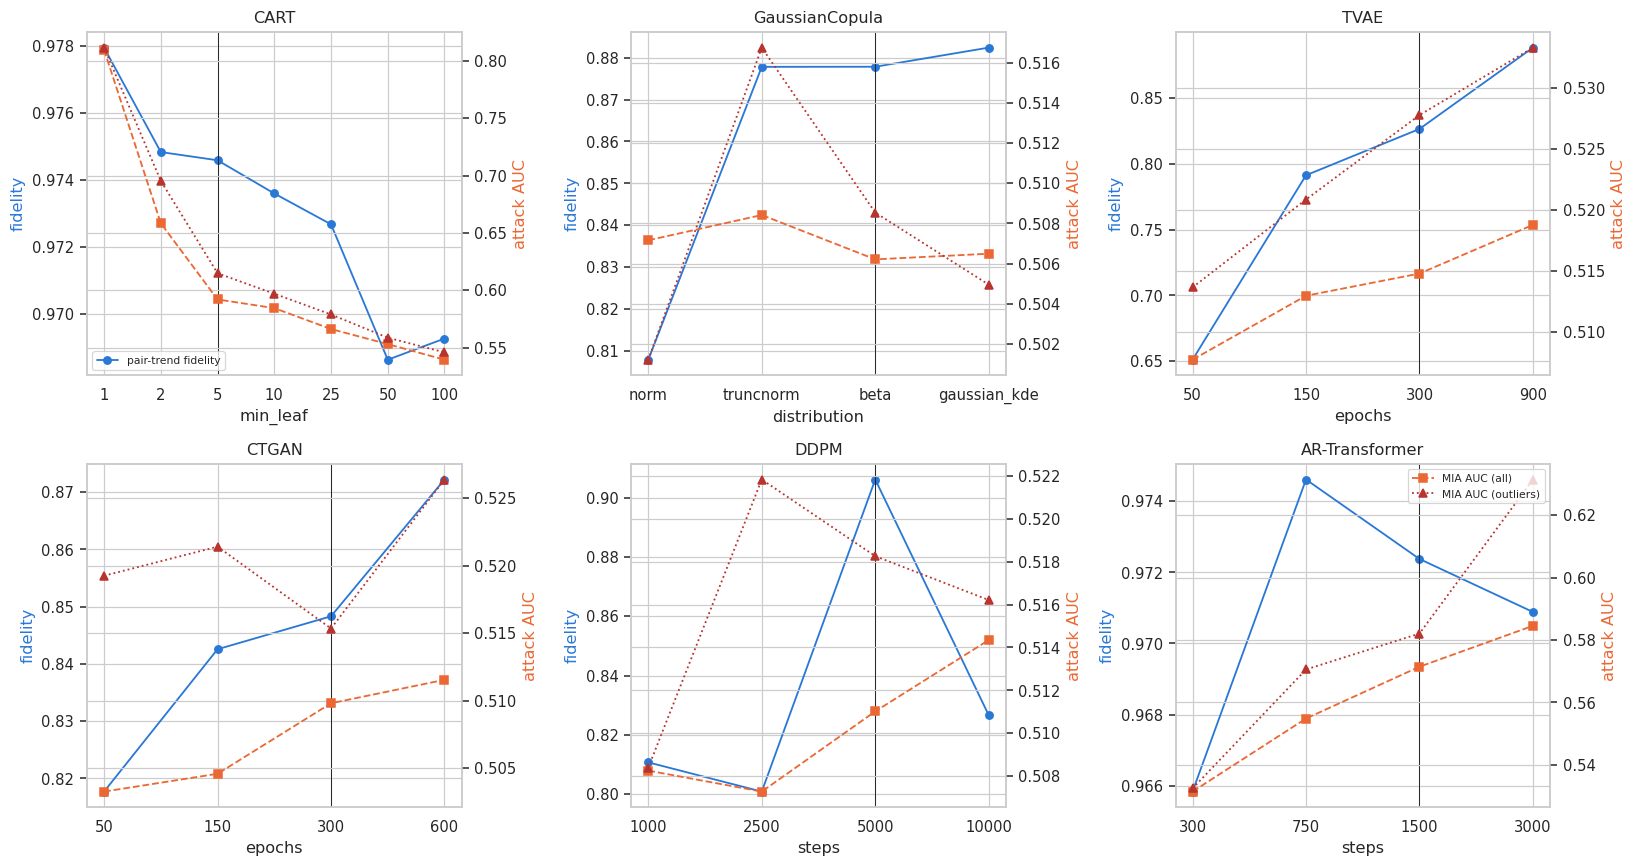

In [3]:
summ = TU.groupby(["generator", "param", "value"], sort=False)[["pair", "util_ratio", "detect_auc", "exact_match_syn", "dcr_share", "mia_auc_max",
                                                                "mia_tpr1_max", "mia_auc_outlier", "anon_link", "anon_infer"]].mean()
summ.to_csv(f"{OUT}/tables/X3_tuning_summary.csv"); display(summ.round(3))
fig, axes = plt.subplots(2, 3, figsize=(15, 8)); axes = axes.ravel()
for ax, (g, (param, values, default, _)) in zip(axes, GRID.items()):
    s = TU[TU.generator == g].groupby("value", sort=False)[["pair", "mia_auc_max", "mia_auc_outlier"]].mean().reindex([str(v) for v in values])
    ax.plot(range(len(s)), s.pair, "o-", color="#2a78d6", label="pair-trend fidelity"); ax.set_ylabel("fidelity", color="#2a78d6")
    ax.set_xticks(range(len(s))); ax.set_xticklabels(s.index, rotation=0); ax.set_xlabel(param); ax.set_title(g)
    ax2 = ax.twinx(); ax2.plot(range(len(s)), s.mia_auc_max, "s--", color="#eb6834", label="MIA AUC (all)"); ax2.plot(range(len(s)), s.mia_auc_outlier, "^:", color="#b8342f", label="MIA AUC (outliers)")
    ax2.set_ylabel("attack AUC", color="#eb6834"); ax.axvline(values.index(default), color="k", lw=0.6)
axes[0].legend(loc="lower left", fontsize=7); axes[0].figure.axes[-1].legend(loc="upper right", fontsize=7)
plt.tight_layout(); fig.savefig(f"{OUT}/figures/X3_tuning_paths.png"); plt.show()

## Within-generator correlation and the "tune for fidelity" scenario

In [4]:
TU["pair_rank"] = TU.groupby(["generator", "seed"]).pair.rank(pct=True); TU["mia_rank"] = TU.groupby(["generator", "seed"]).mia_auc_max.rank(pct=True)
TU["out_rank"] = TU.groupby(["generator", "seed"]).mia_auc_outlier.rank(pct=True)
rho = sa.spearman_boot(TU.pair_rank, TU.mia_rank); rho_o = sa.spearman_boot(TU.pair_rank, TU.out_rank)
per_gen = {g: stats.spearmanr(s.pair, s.mia_auc_max)[0] for g, s in TU.groupby("generator")}
print(f"pooled within-generator rho(pair, MIA AUC) = {rho[0]:.2f} [{rho[1]:.2f}, {rho[2]:.2f}]; outliers: {rho_o[0]:.2f} [{rho_o[1]:.2f}, {rho_o[2]:.2f}]")
sel = []
for (g, seed), s in TU.groupby(["generator", "seed"]):
    best = s.loc[s.pair.idxmax()]; dflt = s[s.is_default].iloc[0]
    sel.append(dict(generator=g, seed=seed, chosen=best.value, default=dflt.value, d_pair=best.pair - dflt.pair, d_util=best.util_ratio - dflt.util_ratio,
                    d_mia=best.mia_auc_max - dflt.mia_auc_max, d_tpr1=best.mia_tpr1_max - dflt.mia_tpr1_max, d_outlier=best.mia_auc_outlier - dflt.mia_auc_outlier,
                    d_link=best.anon_link - dflt.anon_link))
SEL = pd.DataFrame(sel); SEL.to_csv(f"{OUT}/tables/X3_fidelity_selection.csv", index=False)
json.dump(dict(rho_pair_mia=rho, rho_pair_outlier=rho_o, per_generator=per_gen), open(f"{OUT}/tables/X3_rho.json", "w"), indent=1)
display(SEL.groupby("generator")[["d_pair", "d_util", "d_mia", "d_tpr1", "d_outlier", "d_link"]].mean().round(4))
print(f"Notebook runtime: {(time.time()-T0)/60:.1f} min")

pooled within-generator rho(pair, MIA AUC) = 0.48 [0.28, 0.65]; outliers: 0.36 [0.15, 0.54]


,d_pair,d_util,d_mia,d_tpr1,d_outlier,d_link
generator,,,,,,
AR-Transformer,0.0022,-0.0005,-0.0166,-0.0051,-0.0115,-0.0003
CART,0.0034,0.0044,0.2178,0.1595,0.1968,0.3605
CTGAN,0.0239,0.0285,0.0017,0.0008,0.0110,-0.0007
DDPM,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
GaussianCopula,0.0046,0.0260,0.0003,-0.0008,-0.0036,-0.0087
TVAE,0.0617,0.0129,0.0040,0.0025,0.0055,0.0001


Notebook runtime: 115.7 min
